# Allocation Drift and Rebalancing

**Family:** Finance & investment &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Finance & investment:* Performance, risk, portfolios, markets, rates, derivatives and valuation, the everyday charts of investors and analysts.

> ⚠️ Educational examples with simulated or historical data. Not investment advice; past performance does not predict future returns.

## Design purpose

Two 100% stacked area panels show how a portfolio's weights evolve when markets move: with periodic rebalancing the weights snap back to target, without it they drift towards whatever performed best. The comparison makes the hidden risk of "set and forget" visible: a 60/40 portfolio quietly becomes a much more aggressive one.

## When to use

- Explain why and how often to rebalance
- Show how far a portfolio has drifted from its policy weights
- Compare rebalancing rules (calendar vs. threshold)

## Avoid when

- More than five or six holdings (group into asset classes)
- The weights barely move (show a small table instead)

## Alternatives

- Line chart of the equity weight only, with the target band shaded
- Stacked bars at each rebalance date

## Design tips

- Keep the same asset order and colors in both panels
- Draw the target weights as thin reference lines
- Use 2px surface-colored gaps between bands, not borders

## Example

A simulated 60% equities / 30% bonds / 10% cash portfolio, 2015–2024, rebalanced every January vs. never rebalanced. Simple daily returns. Not investment advice.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

from matplotlib.ticker import PercentFormatter
import matplotlib.dates as mdates

### Data

In [2]:
rng = np.random.default_rng(21)
dates = pd.bdate_range("2015-01-01", "2024-12-31")
n = len(dates)
eq = 0.00045 + rng.standard_t(4, n) * 0.0095 / np.sqrt(2)
eq[(dates >= "2020-02-20") & (dates <= "2020-03-23")] -= 0.012
bonds = 0.00012 + rng.normal(0, 0.0035, n)
cash = np.full(n, 0.00006)
asset_rets = pd.DataFrame({"Equities": eq, "Bonds": bonds, "Cash": cash}, index=dates)
target = pd.Series({"Equities": 0.6, "Bonds": 0.3, "Cash": 0.1})
asset_rets.head()

,Equities,Bonds,Cash
2015-01-01,0.002061,-0.000068,0.00006
2015-01-02,0.013092,0.000395,0.00006
2015-01-05,-0.009213,0.007443,0.00006
2015-01-06,0.005421,0.002432,0.00006
2015-01-07,-0.026766,0.003312,0.00006


### Plot

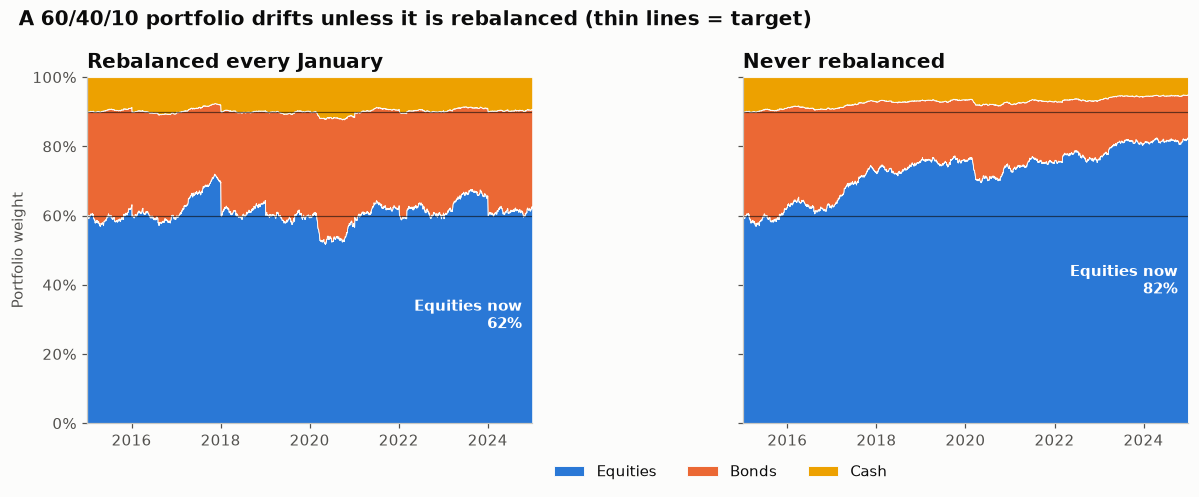

In [3]:
def simulate(rebalance):
    holdings = target.values.copy()
    out = np.empty((len(asset_rets), len(target)))
    years = asset_rets.index.year
    for i, r in enumerate(asset_rets.values):
        if rebalance and i > 0 and years[i] != years[i - 1]:
            holdings = holdings.sum() * target.values
        holdings = holdings * (1 + r)
        out[i] = holdings / holdings.sum()
    return pd.DataFrame(out, index=asset_rets.index, columns=target.index)

panels = [("Rebalanced every January", simulate(True)), ("Never rebalanced", simulate(False))]
colors = [PALETTE[0], PALETTE[1], PALETTE[3]]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True)
for ax, (title, w) in zip(axes, panels):
    ax.stackplot(w.index, w.T.values, colors=colors, labels=w.columns, edgecolor="#fcfcfb", linewidth=0.6)
    for cum in target.cumsum().values[:-1]:
        ax.axhline(cum, color="#0b0b0b", linewidth=0.8, alpha=0.6)
    ax.text(w.index[-60], w["Equities"].iloc[-1] / 2, f"Equities now\n{w['Equities'].iloc[-1]:.0%}",
            fontsize=9.5, ha="right", va="center", color="white", weight="bold")
    ax.xaxis.set_major_locator(mdates.YearLocator(2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.set_title(title)
    ax.set_ylim(0, 1)
    ax.margins(x=0)
    ax.grid(False)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
axes[0].set_ylabel("Portfolio weight")
axes[1].legend(loc="upper center", bbox_to_anchor=(-0.05, -0.08), ncol=3)
fig.suptitle("A 60/40/10 portfolio drifts unless it is rebalanced (thin lines = target)", x=0.02,
             ha="left", fontsize=13, weight="bold")
fig.tight_layout()
plt.show()

## How to read it

In both panels the bands are the share of each asset, adding to 100%. On the left the equity band jumps back to 60% each January. On the right it keeps growing with the stock market, so the portfolio ends up far riskier than its 60/40 label suggests.

---
Standalone script: [`allocation_drift.py`](allocation_drift.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)